In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
import chart_studio.plotly as py
import plotly.graph_objs as go
from plotly.offline import iplot, init_notebook_mode
from sklearn.preprocessing import StandardScaler, LabelEncoder
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier


In [2]:
data = pd.read_csv("city_day.csv")
data['Date'] = pd.to_datetime(data['Date'])
data.rename(columns = {'AQI_Bucket':'Air_quality'}, inplace = True)
data.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,Air_quality
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   City         29531 non-null  object        
 1   Date         29531 non-null  datetime64[ns]
 2   PM2.5        24933 non-null  float64       
 3   PM10         18391 non-null  float64       
 4   NO           25949 non-null  float64       
 5   NO2          25946 non-null  float64       
 6   NOx          25346 non-null  float64       
 7   NH3          19203 non-null  float64       
 8   CO           27472 non-null  float64       
 9   SO2          25677 non-null  float64       
 10  O3           25509 non-null  float64       
 11  Benzene      23908 non-null  float64       
 12  Toluene      21490 non-null  float64       
 13  Xylene       11422 non-null  float64       
 14  AQI          24850 non-null  float64       
 15  Air_quality  24850 non-null  object        
dtypes: d

<AxesSubplot:>

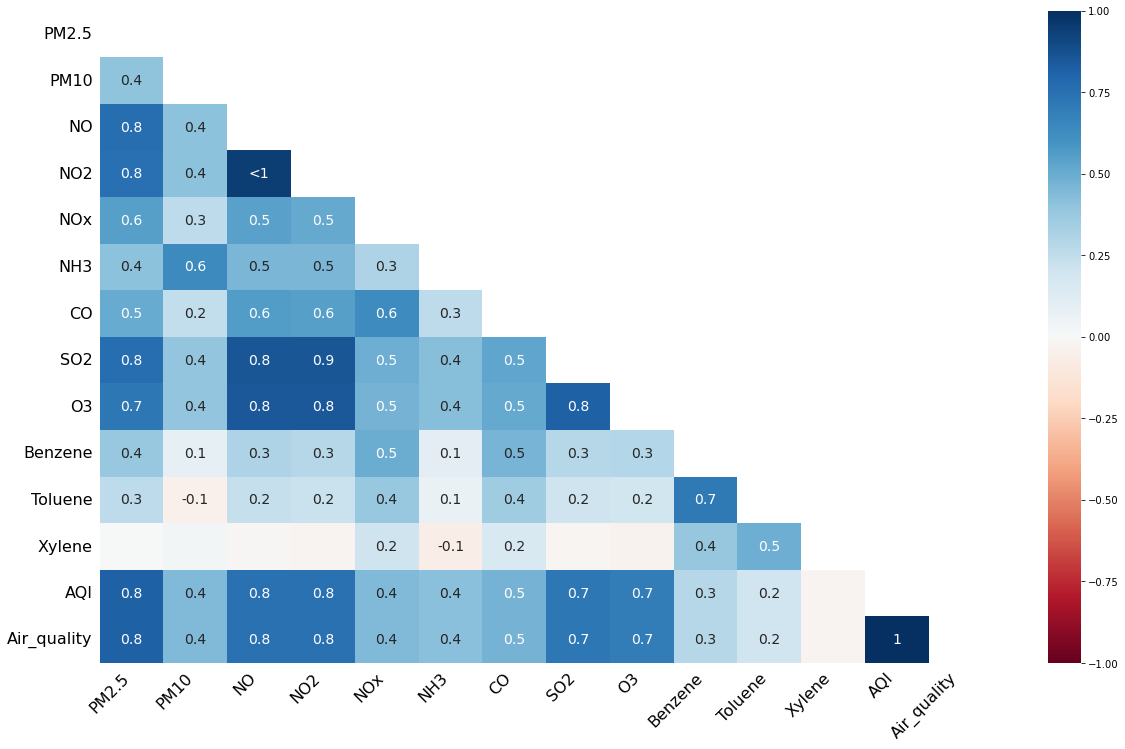

In [4]:
msno.heatmap(data)

In [5]:
df1 = data.copy()
df1['PM2.5']=df1['PM2.5'].fillna((df1['PM2.5'].median()))
df1['PM10']=df1['PM10'].fillna((df1['PM10'].median()))
df1['NO']=df1['NO'].fillna((df1['NO'].median()))
df1['NO2']=df1['NO2'].fillna((df1['NO2'].median()))
df1['NOx']=df1['NOx'].fillna((df1['NOx'].median()))
df1['NH3']=df1['NH3'].fillna((df1['NH3'].median()))
df1['CO']=df1['CO'].fillna((df1['CO'].median()))
df1['SO2']=df1['SO2'].fillna((df1['SO2'].median()))
df1['O3']=df1['O3'].fillna((df1['O3'].median()))
df1['Benzene']=df1['Benzene'].fillna((df1['Benzene'].median()))
df1['Toluene']=df1['Toluene'].fillna((df1['Toluene'].median()))
df1['Xylene']=df1['Xylene'].fillna((df1['Xylene'].median()))
df1['AQI']=df1['AQI'].fillna((df1['AQI'].median()))
df1['Air_quality']=df1['Air_quality'].fillna('Moderate')

## Preprocessing

<AxesSubplot:>

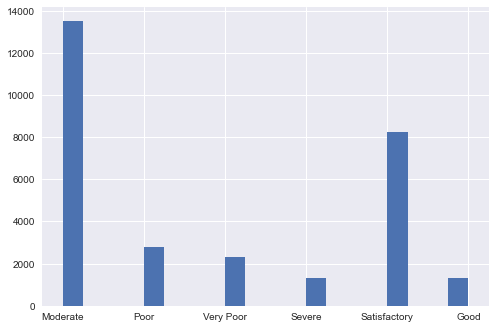

In [6]:
plt.style.use('seaborn')
df1['Air_quality'].hist(bins=20)

In [7]:
cor = df1.corr()
cor.style.background_gradient(cmap='coolwarm')

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
PM2.5,1.000000,0.520767,0.435245,0.358287,0.375938,0.164615,0.093695,0.120451,0.166064,0.030539,0.132609,0.087813,0.633654
PM10,0.520767,1.000000,0.433864,0.352396,0.416523,0.200548,0.023932,0.165468,0.208398,0.027522,0.126400,0.030257,0.447686
NO,0.435245,0.433864,1.000000,0.465848,0.747409,0.155804,0.221445,0.174881,0.020788,0.045202,0.151930,0.084393,0.438039
NO2,0.358287,0.352396,0.465848,1.000000,0.581938,0.151731,0.361750,0.388413,0.289435,0.042179,0.297913,0.188965,0.531952
NOx,0.375938,0.416523,0.747409,0.581938,1.000000,0.129433,0.231878,0.205912,0.089095,0.049004,0.184764,0.085447,0.436282
NH3,0.164615,0.200548,0.155804,0.151731,0.129433,1.000000,-0.014252,-0.048679,0.076295,0.004093,0.020040,-0.030328,0.097916
CO,0.093695,0.023932,0.221445,0.361750,0.231878,-0.014252,1.000000,0.476784,0.043311,0.066022,0.285559,0.181215,0.650475
SO2,0.120451,0.165468,0.174881,0.388413,0.205912,-0.048679,0.476784,1.000000,0.160489,0.038955,0.273314,0.249808,0.454182
O3,0.166064,0.208398,0.020788,0.289435,0.089095,0.076295,0.043311,0.160489,1.000000,0.023982,0.135498,0.084323,0.199100
Benzene,0.030539,0.027522,0.045202,0.042179,0.049004,0.004093,0.066022,0.038955,0.023982,1.000000,0.693310,0.094190,0.052027


In [8]:
df1['City'].unique()

array(['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru',
       'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore',
       'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad',
       'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai',
       'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram',
       'Visakhapatnam'], dtype=object)

In [9]:
y = df1["Air_quality"]
x = df1[['PM2.5','PM10','NO2','CO','SO2','O3']]


In [10]:
#conda install -c conda-forge imbalanced-learn

In [11]:
from imblearn.over_sampling import SMOTE
oversample = SMOTE()
x,y = oversample.fit_resample(x,y)
print('Classes and number of values in trainset after SMOTE:',Counter(y))

Classes and number of values in trainset after SMOTE: Counter({'Moderate': 13510, 'Poor': 13510, 'Very Poor': 13510, 'Severe': 13510, 'Satisfactory': 13510, 'Good': 13510})


In [12]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 0)

In [13]:
X_test

,PM2.5,PM10,NO2,CO,SO2,O3
28197,48.110000,92.400000,45.090000,1.050000,14.040000,38.940000
76658,133.557867,240.896211,87.466150,1.290360,23.468220,107.196122
25090,124.300000,95.680000,29.340000,2.130000,27.010000,93.410000
18008,48.570000,144.540000,9.390000,0.330000,94.320000,47.120000
18313,48.570000,95.680000,21.690000,0.890000,9.160000,30.840000
...,...,...,...,...,...,...
80998,175.120159,95.680000,11.852998,6.839418,5.028056,30.735616
53277,18.417458,45.962462,17.390087,0.809803,6.670971,11.850584
68843,176.042824,515.385669,49.734151,0.862850,37.247275,48.961999
39359,19.327191,95.680000,23.114010,0.000000,9.160000,30.840000


In [14]:
y_test

28197    Satisfactory
76658       Very Poor
25090            Poor
18008        Moderate
18313        Moderate
             ...     
80998       Very Poor
53277    Satisfactory
68843          Severe
39359            Good
54796    Satisfactory
Name: Air_quality, Length: 24318, dtype: object

In [15]:

print('Classes and number of values in trainset',Counter(y_train))

Classes and number of values in trainset Counter({'Severe': 9510, 'Moderate': 9498, 'Good': 9477, 'Satisfactory': 9443, 'Very Poor': 9442, 'Poor': 9372})


### 2. Random Forest

In [16]:
rf = RandomForestClassifier(n_estimators=40, random_state=23)
rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=40, random_state=23)

In [17]:
rf.score(X_train,y_train)

0.9983786260618237

In [18]:
from sklearn.metrics import accuracy_score
y_pred = rf.predict(X_test )
accuracy_score(y_pred,y_test) 

0.9022534747923349

In [19]:
import sklearn.metrics

In [20]:
print(sklearn.metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        Good       0.93      0.96      0.95      4033
    Moderate       0.85      0.79      0.82      4012
        Poor       0.88      0.90      0.89      4138
Satisfactory       0.85      0.87      0.86      4067
      Severe       0.97      0.97      0.97      4000
   Very Poor       0.93      0.93      0.93      4068

    accuracy                           0.90     24318
   macro avg       0.90      0.90      0.90     24318
weighted avg       0.90      0.90      0.90     24318



In [21]:
y_pred = rf.predict(X_test )
y_true=y_test


from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_true,y_pred)
cm

array([[3868,   35,    4,  126,    0,    0],
       [  34, 3170,  294,  474,   13,   27],
       [   0,  208, 3727,    9,   10,  184],
       [ 237,  294,   14, 3522,    0,    0],
       [   1,    9,   11,    8, 3881,   90],
       [   0,   23,  174,    1,   97, 3773]], dtype=int64)

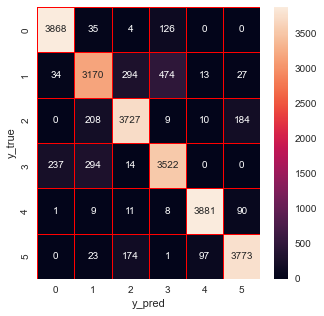

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

f, ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidths=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("y_pred")
plt.ylabel("y_true")
plt.show()

In [23]:
import pickle

pickle.dump(rf,open('airs.pkl','wb'))
airs = pickle.load(open('airs.pkl','rb'))